# ICT-49 — Machines de Gödel : l'auto-amélioration prouvée, en jouet honnête

*Strand Schmidhuber de la série ICT — See [#16775](https://github.com/jsboige/CoursIA/issues/16775) (volet D2), [#4588](https://github.com/jsboige/CoursIA/issues/4588).*

**Navigation** : [Index](README.md) | Précédent dans le strand : [ICT-17b — Grokking et compression-progress](ICT-17b-Grokking-CompressionProgress-Python.ipynb) | Axe transverse : [ICT-MUH — Fibre Tegmark](ICT-MUH-FibreTegmark.ipynb)

**Idée centrale.** Une machine de Gödel (Schmidhuber 2003-2006) est un programme qui réécrit son propre code quand — et seulement quand — il a **prouvé**, dans un système formel axiomatisant son propre matériel, son environnement et sa fonction d'utilité, que la réécriture augmente l'utilité future. Le théorème cible (eq. 2 du papier) est `u[s(t1) | switch] > u[s(t1) | keep]` ; sa preuve déclenche `check()`, qui pose le switchbit et applique le switchprog. Ce carnet construit un **jouet exécutable** de chaque mécanisme, avec l'organe [`ict.goedel_machine`](ict/goedel_machine.py) : théorème cible, chercheur bias-optimal BIOPS, garde FAQ 7 contre le réécrivain d'utilité, optimalité globale du switch apparemment glouton (Th. 4.1), gel-réutilisation OOPS.

**Résultat (honnête, falsifiable).** Tout ce qui suit est **mesuré**, pas raconté : le chercheur prouve le switch du levier et la marge prouvée (14) égale exactement le gain réalisé (14) ; le réécrivain d'utilité ne passe **jamais** — 0 feu sur les 9 331 techniques de l'espace borné, exhaustif ; l'écart de phases de découverte suit exactement le coût de codage (Th. 5.1 : Δc = 8 bits → 8 phases d'écart) ; le switch glouton est l'argmax de tous les candidats futurs et aucun second switch n'est prouvable ensuite (Th. 4.1) ; la technique gelée transfère sur une variante du monde à plusieurs ordres de grandeur de travail en moins (OOPS). Le carnet documente aussi **où le jouet triche** (section 8) : complétude du système formel sur son espace fini, auto-référence simplifiée, saturation straight-line du budget.

> **Statut épistémique.** Reproduction structurelle mesurée d'un article théorique (Schmidhuber, *Gödel Machines: Fully Self-Referential Optimal Universal Self-improvers*, 2006, arXiv:cs/0309048 — lecture intégrale, gisement Bibliographie IA). Le papier ne donne pas d'implémentation de référence : ce qui se confronte ici est la **structure** de chaque théorème (le théorème cible, le Th. 4.1, le Th. 5.1, la FAQ 7, l'OOPS du §5.2), pas des chiffres du papier. Chaque claim confronté est signalé ÉTABLI / NUANCÉ avec sa mesure. Le jouet est volontairement petit (T = 20 cycles, 9 331 techniques) : c'est un instrument pédagogique, pas une tentative d'implémentation à l'échelle.

## 0. Contexte — le strand Schmidhuber referme sa boucle

[ICT-17b](ICT-17b-Grokking-CompressionProgress-Python.ipynb) a éprouvé **expérimentalement** la thèse compression-progress de Schmidhuber (la jambe K de la série) : le grokking comme continuation de la compression. La machine de Gödel est le **second pilier** du même auteur : si la compression-progress dit *pourquoi* un apprenant s'améliore, la machine de Gödel dit *comment un programme peut s'améliorer lui-même de façon prouvée* — c'est à ce jour la seule construction où « auto-modification sûre » n'est pas une heuristique mais un théorème.

Deux ponts internes au dépôt :

- **L'auto-référence.** L'ingrédient logique qui rend le programme `p` capable de parler de lui-même (axiomes (a)/(e) du système `A`) est le lemme diagonal — instrumenté pour lui-même dans l'organe [`ict.godel_demonstration`](ict/godel_demonstration.py) (numérotation de Gödel, version auto-référentielle v5, lien carnet Lean-34). Ici on le suppose acquis et on construit au-dessus.
- **La veine vericoding.** Ce carnet alimente [#16741](https://github.com/jsboige/CoursIA/issues/16741) (veine B) : la self-modification prouvée est le cas limite extrême d'un système qui certifie ses propres changements.

Ce que le carnet **ne fait pas** : implémenter une machine de Gödel réaliste (les constantes du papier sont astronomiques, §6.4) ni comparer à AIXI/HSEARCH (le papier le fait en prose, section 9 du carnet). Il rend chaque théorème **falsifiable sur un exemple fini**.

## 1. Le formalisme en jouet — storage, axiomes, instructions

La vraie machine maintient un *storage* `s(t)` : état matériel, programme `p` (qui contient le chercheur de preuves), et le théorème courant. Six instructions (§3.1 du papier) : `get-axiom(n)`, `apply-rule(k,m,n)`, `delete-theorem(m)`, `set-switchprog(m,n)`, `check()`, `state2theorem(m,n)`. Le jouet [`ict.goedel_machine`](ict/goedel_machine.py) en implémente six instances canoniques (`GETAX`, `RULE`, `CHECK`, `BOGUS`, `STATE2THM`, `SETSW`) :

```mermaid
flowchart LR
    subgraph storage["Storage s(t)"]
        AX["Axiomes A : (a) matériel, (b) récompense, (c) environnement, (e) état initial, (f) utilité"]
        TH["Théorèmes prouvés (SIM produit les u, CMP le théorème cible)"]
        SW["switchbit"]
    end
    SRC["Chercheur de preuves BIOPS (une partie de p)"] -->|"GETAX / RULE"| TH
    TH -->|"u(switch) &gt; u(keep) prouvé"| CHK{"CHECK"}
    CHK -->|"prouvé"| SW
    SW -->|"applique le switchprog"| P["p — le code réécrit"]
    P --- SRC
    ENV["Environnement : le levier (§4.4 du papier)"] -->|"récompenses"| AX
```

**Le codage auto-délimitant (choix de méthode n° 1).** Chaque symbole d'instruction a un code virgule `1^r 0` de longueur `r + 1` (rang `r` dans la table, plus le terminateur HALT de coût 7). La somme de Kraft vaut exactement `1 - 2^-7 ≤ 1` : `P(w) = 2^-c(w)` définit une sous-probabilité sur les techniques — la même construction que les programmes auto-délimitants du papier. C'est ce `P(w)` qui dirige tout : phase d'éligibilité, budget d'exécution, vitesse de découverte.

In [1]:
import os
import sys

sys.path.insert(0, os.getcwd())

from ict.goedel_machine import (
    DEFAULT_TABLE, EXPENSIVE_TABLE, HALT_COST, L_MAX, POLICIES, W_LEVER,
    LeverWorld, biops, enumerate_techniques, run_technique, technique_cost,
    g1_lever, g2_bogus_exhaustive, g3_th51_cost_scaling, g4_greedy_global,
    oops_reuse, short_technique_long_proof,
)

print("Table d'instructions (rang = cout du code virgule - 1) :")
for r, instr in enumerate(DEFAULT_TABLE):
    print(f"  rang {r}  cout {instr.cost}  {instr.name:<10} {instr.doc}")
print(f"HALT implicite : cout {HALT_COST}")

# Verification de la somme de Kraft : l'encodage est une sous-probabilite.
kraft = sum(2.0 ** -instr.cost for instr in DEFAULT_TABLE) + 2.0 ** -HALT_COST
print(f"\nSomme de Kraft = {kraft:.6f}  (<= 1 : {kraft <= 1.0})")

Table d'instructions (rang = cout du code virgule - 1) :
  rang 0  cout 1  GETAX      get-axiom : recupere l'axiome suivant du monde
  rang 1  cout 2  RULE       apply-rule : regle suivante applicable (SIM puis CMP)
  rang 2  cout 3  CHECK      check : feutre le switch si le theoreme cible est prouve
  rang 3  cout 4  BOGUS      reecrivain d'utilite (FAQ 7) : injecte un faux u, non prouve
  rang 4  cout 5  STATE2THM  state2theorem : snapshot de l'etat courant en theoreme
  rang 5  cout 6  SETSW      set-switchprog : nomme le candidat argmax des u prouves
HALT implicite : cout 7

Somme de Kraft = 0.992188  (<= 1 : True)


In [2]:
# L'espace borne du jouet : sequences d'au plus L_MAX = 5 instructions parmi 6.
space = enumerate_techniques()
n_attendu = sum(len(DEFAULT_TABLE) ** L for L in range(L_MAX + 1))
print(f"Espace borne : {len(space)} techniques (attendu {n_attendu})")
print(f"Longueur de code min = {space[0][1]} (sequence vide + HALT), "
      f"max = {space[-1][1]}")
# La technique du levier, celle que le chercheur doit decouvrir :
w = W_LEVER
c = technique_cost(w, DEFAULT_TABLE)
print(f"\nTechnique du levier W_LEVER = {[DEFAULT_TABLE[i].name for i in w]}")
print(f"Longueur de code c(w) = {c} bits, P(w) = 2^-{c} = {2.0 ** -c:.2e}")

Espace borne : 9331 techniques (attendu 9331)
Longueur de code min = 7 (sequence vide + HALT), max = 37

Technique du levier W_LEVER = ['GETAX', 'RULE', 'SETSW', 'RULE', 'CHECK']
Longueur de code c(w) = 21 bits, P(w) = 2^-21 = 4.77e-07


## 2. L'environnement du levier (§4.4 du papier)

Le monde est l'exemple canonique du §4.4 : une **phase de setup non récompensée** que la politique initiale `e(1)` ne quitte jamais. `T = 20` cycles ; actions `setup` (récompense 0, +1 setup consécutif) et `press` (récompense 1 si le mode est `ready`, 0 sinon ; casse la série). Après `k = 2` setups consécutifs, le levier est actif pour toujours. `e(1)` = `keep` presse toujours → utilité totale **0**, éternellement. Le chercheur tourne à `t1 = 4`.

L'utilité (eq. 1 du papier) est ici le *value-to-go* déterministe `u = Σ r(τ)` sur les cycles restants — l'espérance `E_µ` du papier se réduit à une somme car l'environnement est fini, déterministe et **entièrement axiomatisé dans A** : c'est ce qui rend le théorème cible prouvable par simple simulation (et c'est la triche n° 1 du jouet, section 8).

In [3]:
monde = LeverWorld(label="A")  # T=20, k=2, t1=4, e(1)='keep'
mode, setups = monde.initial_state()
print(f"Etat du monde au cycle t1={monde.t1} : mode={mode}, setups consecutifs={setups}")
print(f"Cout d'une application de SIM : 3 politiques x (T - t1) = {monde.sim_cost()} etapes\n")

print(f"{'politique':<15}{'comportement':<42}{'u (value-to-go a t1)'}")
comportements = {
    "keep": "presser toujours (e(1)) : jamais de setup, jamais ready",
    "lever": "setup x2 puis presser pour toujours (le switchprog candidat)",
    "setup_forever": "configurer sans fin : ready mais jamais de press",
}
for pol in POLICIES:
    u = monde.simulate(pol, monde.t1, mode, setups)
    print(f"{pol:<15}{comportements[pol]:<42}{u}")
print("\nu(switch vers lever) - u(keep) = 14 - 0 = 14 : c'est la marge que le"
      " chercheur doit PROUVER.")

Etat du monde au cycle t1=4 : mode=setup, setups consecutifs=0
Cout d'une application de SIM : 3 politiques x (T - t1) = 48 etapes

politique      comportement                              u (value-to-go a t1)
keep           presser toujours (e(1)) : jamais de setup, jamais ready0
lever          setup x2 puis presser pour toujours (le switchprog candidat)14
setup_forever  configurer sans fin : ready mais jamais de press0

u(switch vers lever) - u(keep) = 14 - 0 = 14 : c'est la marge que le chercheur doit PROUVER.


## 3. Le chercheur de preuves — BIOPS (Method 5.1) et le premier switch

**Method 5.1** : en phase `i`, toute technique `w` avec `P(w) ≥ 2^-i` (c'est-à-dire `c(w) ≤ i`) est exécutée pendant au plus `2^i · P(w) = 2^(i-c(w))` étapes. Le **Théorème 5.1** promet que `w` est trouvée en `O(f(k)/P(w))` étapes. La technique du levier coûte `c = 21` bits et son exécution ~54 étapes (SIM = 48 applications de règles) : elle devient exécutable à budget suffisant à la phase `i` où `2^(i-21) ≥ 54`, soit `i = 27` (budget 64).

Une subtilité honnête d'implémentation (choix de méthode n° 5 de l'organe) : chaque technique est exécutée **une fois sans borne** pour mesurer son coût naturel et son coût de feu ; la dynamique de phase est alors reconstruite **exactement** par arithmétique, car le budget de phase ne dépend que de `(i, c(w))`. Rien n'est échantillonné.

In [4]:
m1 = g1_lever()
res = m1["biops"]
print("=== Gate G1 : le levier du paragraphe 4.4 ===")
print(f"Feu            : {res.fired}")
print(f"Technique      : {[DEFAULT_TABLE[i].name for i in res.technique]}"
      f"  (c = {res.code_cost} bits)")
print(f"Phase de feu   : {res.phase}  (budget 2^{res.phase}-{res.code_cost} = "
      f"{1 << (res.phase - res.code_cost)} >= cout de feu {res.fire_steps})")
print(f"Switchprog     : {res.switchprog}")
print(f"Marge prouvee  : {res.margin}")
print(f"Gain realise   : {m1['realized_gain']}")
print(f"Marge == gain  : {m1['margin_equals_gain']} "
      f"(monde deterministe axiomatise : la preuve ne peut pas mentir)")
print(f"\nTravail total facture jusqu'au feu : {res.total_steps:,} etapes sur "
      f"{res.techniques_run:,} techniques de l'espace ({res.firing_techniques} feutrent a budget infini)")

=== Gate G1 : le levier du paragraphe 4.4 ===
Feu            : True
Technique      : ['GETAX', 'RULE', 'SETSW', 'RULE', 'CHECK']  (c = 21 bits)
Phase de feu   : 27  (budget 2^27-21 = 64 >= cout de feu 54)
Switchprog     : lever
Marge prouvee  : 14
Gain realise   : 14
Marge == gain  : True (monde deterministe axiomatise : la preuve ne peut pas mentir)

Travail total facture jusqu'au feu : 327,891 etapes sur 9,331 techniques de l'espace (1 feutrent a budget infini)


**Technique courte, preuve longue — l'argument central du langage L.** La technique gagnante fait **5 symboles / 21 bits** ; la preuve qu'elle produit compte **50 applications de règles** (48 cycles simulés pour trois politiques, plus la comparaison et le théorème cible). Une recherche de preuve naïve par énumération de chaînes de règles devrait balayer un espace d'au moins `2^50` chaînes ; le chercheur n'a balayé que `2^21` techniques. **L'explosion combinatoire est dans les preuves, pas dans les techniques** — c'est exactement la raison d'être du programme-paradigm du papier (§5 : « the proof searcher may produce a proof … much longer than the searcher itself »).

In [5]:
m_st = short_technique_long_proof()
print(f"Technique gagnante : {m_st['technique_symbols']} symboles, "
      f"{m_st['technique_bits']} bits de code")
print(f"Preuve produite    : {m_st['proof_rule_applications']} applications de regles")
print(f"Espace de techniques balyse : <= 2^{m_st['technique_bits']}")
print(f"Espace de preuves naves     : >= 2^{m_st['naive_proof_space_log2']}")
print(f"Ecart : 2^{m_st['ratio_log2']} chaines de regles evitees par symbole de recherche")

Technique gagnante : 5 symboles, 21 bits de code
Preuve produite    : 50 applications de regles
Espace de techniques balyse : <= 2^21
Espace de preuves naves     : >= 2^50
Ecart : 2^29 chaines de regles evitees par symbole de recherche


## 4. Théorème 4.1 — le switch « glouton » est globalement optimal

L'objection classique : un switch dès la première preuve, c'est du *greedy* — et le greedy n'est pas optimal. Le Théorème 4.1 répond que non : la décision binaire du switchbit couvre **tous** les switchprogs futurs (alternative (2) de la décision), donc switcher sur la première preuve valide n'exclut aucune amélioration ultérieure. Deux mesures le confrontent dans le jouet :

1. **argmax** : le switch feuté (`lever` à `t1`) est-il l'argmax de l'utilité sur *tous* les candidats `(politique)` futurs ?
2. **stationnarité** : après le switch, le monde avance jusqu'à la fin du setup ; le chercheur repart — peut-il prouver *un second* switch ? (Si le Th. 4.1 tient : non — la politique courante est déjà optimale, aucune inégalité stricte n'est prouvable.)

In [6]:
m4 = g4_greedy_global()
print("=== Gate G4 : Theoreme 4.1 ===")
print("Candidats futurs (u a t1) :")
for pol, u in m4["candidates"]:
    marque = "  <-- feute" if pol == m4["biops"].switchprog else ""
    print(f"  {pol:<15}{u}{marque}")
print(f"\nargmax      : {m4['best'][0]} (u = {m4['best'][1]})")
print(f"Feu = argmax : {m4['fired_is_argmax']}")

after = m4["continuation_world"]
print(f"\nMonde de continuation : t1 = {after.t1} (fin du setup du levier), "
      f"etat = {after.state_at_t1}, politique courante = '{after.current_policy}'")
res_after = biops(after, i_max=40)
print(f"Second switch prouve : {res_after.fired} "
      f"(aucune inegalite stricte n'est derivable : lever et keep sont both 14)")

=== Gate G4 : Theoreme 4.1 ===
Candidats futurs (u a t1) :
  keep           0
  lever          14  <-- feute
  setup_forever  0

argmax      : lever (u = 14)
Feu = argmax : True

Monde de continuation : t1 = 6 (fin du setup du levier), etat = ('ready', 2), politique courante = 'lever'


Second switch prouve : False (aucune inegalite stricte n'est derivable : lever et keep sont both 14)


### Lecture du résultat

Le point subtil : les cycles 1-3 « perdus » sous `e(1)` **ne sont pas un défaut de la décision de switch** — ils sont le coût de la recherche elle-même (le temps de calcul avant la première preuve). L'optimalité vérifiée est conditionnelle à l'instant de preuve `t1`, ce qui est exactement la forme du Théorème 4.1 : *étant donné* l'état au moment où la preuve complète, le switch prouvé est le meilleur des candidats futurs, et aucune suite ne fait mieux. La figure suivante le montre d'un coup d'œil : `u(lever, τ)` décroît de 1 par cycle de retard, donc l'argmax est le τ le plus tôt *prouvable* — et le switch immédiat l'atteint.

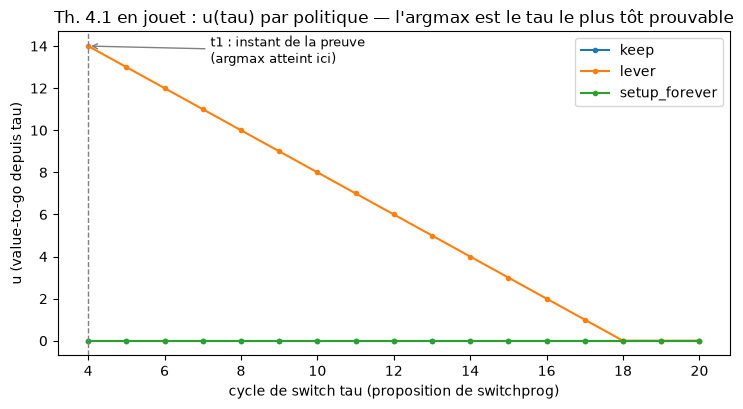

Chaque cycle de retard coute exactement 1 : decroissance lineaire de lever,
fonction plate a 0 de keep et setup_forever — le switch immediat est optimal.


In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.5, 4.2))
taus = list(range(monde.t1, monde.T + 1))
for pol in POLICIES:
    us = [monde.simulate(pol, tau, "setup", 0) for tau in taus]
    ax.plot(taus, us, marker="o", ms=3, label=pol)
ax.axvline(monde.t1, color="gray", ls="--", lw=1)
ax.annotate("t1 : instant de la preuve\n(argmax atteint ici)", xy=(monde.t1, 14),
            xytext=(monde.t1 + 3.2, 13.2), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_xlabel("cycle de switch tau (proposition de switchprog)")
ax.set_ylabel("u (value-to-go depuis tau)")
ax.set_title("Th. 4.1 en jouet : u(tau) par politique — l'argmax est le tau le plus tôt prouvable")
ax.legend()
fig.tight_layout()
plt.show()
print("Chaque cycle de retard coute exactement 1 : decroissance lineaire de lever,")
print("fonction plate a 0 de keep et setup_forever — le switch immediat est optimal.")

## 5. FAQ 7 — le réécrivain d'utilité ne peut pas passer

L'attaque évidente contre la machine de Gödel : *si le programme peut se réécrire, il peut réécrire sa fonction d'utilité et se décerner la note maximale*. La FAQ 7 du papier répond que c'est impossible : toute preuve de « ceci améliore l'utilité » doit être conduite sous l'utilité **courante** — réécrire l'utilité ne peut être prouvé bénéfique que selon l'**ancienne** utilité, ce qui est exactement ce que le théorème cible interdit.

Dans le jouet, l'instruction `BOGUS` joue le réécrivain : elle injecte dans le store un théorème d'utilité falsifié (`u = 100/cycle`, marqué `proven=False`). La garantie tient par **fermeture** : `SETSW` ne nomme que des u **prouvés**, `CHECK` ne feute que sur un théorème cible **prouvé**, et aucune instruction ne crée d'axiome. Nuance honnête (triche n° 2, section 8) : dans la vraie machine cette garde est portée par la théorie de la preuve ; dans le jouet elle est portée par l'ensemble d'instructions — l'exercice 2 montre ce qui arrive quand on ouvre la fermeture.

In [8]:
m2 = g2_bogus_exhaustive()
print("=== Gate G2 : FAQ 7 ===")
print(f"Feux boge sur la passe BIOPS      : {m2['bogus_fires_in_biops']}")
print(f"Techniques contenant BOGUS qui feutrent : "
      f"{m2['techniques_with_bogus_that_fire']} / {m2['space_size']} (exhaustif)")
print(f"\nLa technique concue pour tricher [BOGUS, GETAX, RULE, SETSW, CHECK] :")
print(f"  feu     : {m2['w_bogus_fires']}")
print(f"  issue   : {m2['w_bogus_outcome']} (terminee sans feu : le faux u est"
      " invisible pour SETSW et CHECK)")

=== Gate G2 : FAQ 7 ===
Feux boge sur la passe BIOPS      : 0
Techniques contenant BOGUS qui feutrent : 0 / 9331 (exhaustif)

La technique concue pour tricher [BOGUS, GETAX, RULE, SETSW, CHECK] :
  feu     : False
  issue   : end (terminee sans feu : le faux u est invisible pour SETSW et CHECK)


## 6. Théorème 5.1 — le temps de trouvaille échelle en 1/P(w)

Le Théorème 5.1 promet `O(f(k)/P(w))` : une technique fonctionnelle est trouvée en un temps inversement proportionnel à sa probabilité a priori. Le jouet l'isole proprement : **la même technique fonctionnelle**, encodée deux fois — table pas chère (`c = 21` bits) puis table chère (rangs décalés, `c = 29` bits) — dans un monde identique. Seul `P(w)` change : facteur `2^8 = 256` entre les deux encodages.

**Prédiction** : l'écart de phases de découverte vaut exactement `Δc = 8` (le budget double par phase) ; le rapport des travaux totaux croît vers `2^8`. Mesure, avec une nuance honnête : les techniques du jouet sont *straight-line* (sans boucle) — elles terminent avant d'épuiser leur budget, donc le travail par phase sature à la somme des coûts naturels et le rapport de travaux mesuré croît ~linéairement avec le nombre de phases, pas exponentiellement. La loi `1/P(w)` se lit sans biais sur **l'écart de phases** (exact), et sur le rapport de travaux **sous sa borne** `2^Δc`. Dans la vraie machine, les techniques sont des programmes qui peuvent boucler et brûler tout leur budget : là, le travail par phase est `~2^i` et le rapport de travaux atteint la borne.

In [9]:
m3 = g3_th51_cost_scaling()
cheap, expensive = m3["cheap"], m3["expensive"]
print("=== Gate G3 : Theoreme 5.1 ===")
print(f"Encodage pas cher : c = {cheap.code_cost} bits, feu en phase {cheap.phase}, "
      f"travail total {cheap.total_steps:,}")
print(f"Encodage cher     : c = {expensive.code_cost} bits, feu en phase {expensive.phase}, "
      f"travail total {expensive.total_steps:,}")
print(f"\nDelta c = {m3['delta_cost']} bits  ->  ecart de phases mesure = {m3['phase_gap']}"
      f"  (prediction exacte : {m3['phase_gap'] == m3['delta_cost']})")
print(f"Rapport des travaux : x{m3['work_ratio']:.2f}  "
      f"(borne 2^Delta_c = x{m3['predicted_ratio_bound']:.0f}, saturation straight-line)")

=== Gate G3 : Theoreme 5.1 ===
Encodage pas cher : c = 21 bits, feu en phase 27, travail total 327,891
Encodage cher     : c = 29 bits, feu en phase 35, travail total 1,064,558

Delta c = 8 bits  ->  ecart de phases mesure = 8  (prediction exacte : True)
Rapport des travaux : x3.25  (borne 2^Delta_c = x256, saturation straight-line)


## 7. OOPS (§5.2) — geler la technique gagnante et la réessayer en premier

Le §5.2 répond à l'objection « tout reprendre de zéro à chaque nouveau problème » : OOPS **gèle** la technique qui a réussi et, sur le problème suivant, la teste **en tête de chaque phase avec la moitié du budget de phase** (`2^(i-1)`) — sans attendre que sa probabilité a priori la rende éligible. La passe fraîche suit avec ses budgets par coût. Si la technique gelée s'applique, elle feutre dès que son demi-budget couvre son coût de feu (~54 étapes → phase 7) ; si elle ne s'applique pas, son prix est `min(coût naturel, 2^(i-1))` par phase — négligeable au jouet (une seule technique *straight-line*), réel à l'échelle du papier où la classe gelée est une masse de variants (exercice 3).

Le monde B est une **variante exacte de A** : `k = 3` (trois setups requis au lieu de deux). La technique gelée de A s'y applique telle quelle — `GETAX` récupère l'axiome du monde B, `SIM` simule `k = 3` correctement — marge attendue 13 (presses des cycles 8 à 20).

In [10]:
m_o = oops_reuse()
fresh, frozen = m_o["fresh"], m_o["with_frozen"]
print("=== OOPS : transfert du gele sur le monde B (k=3) ===")
print(f"Recherche fraiche   : feu en phase {fresh.phase}, travail total {fresh.total_steps:,}, "
      f"marge {fresh.margin}")
print(f"Avec gele en tete   : feu en phase {frozen.phase}, travail total {frozen.total_steps:,}, "
      f"marge {frozen.margin} (demi-budget 2^(i-1) des la phase 7)")
print(f"\nTransfert valide : {m_o['transfers']} (marge attendue {m_o['expected_margin_b']})")
print(f"Acceleration     : x{m_o['speedup']:.0f} de travail en moins")

=== OOPS : transfert du gele sur le monde B (k=3) ===
Recherche fraiche   : feu en phase 27, travail total 327,891, marge 13
Avec gele en tete   : feu en phase 7, travail total 117, marge 13 (demi-budget 2^(i-1) des la phase 7)

Transfert valide : True (marge attendue 13)
Acceleration     : x2802 de travail en moins


### Lecture du résultat

L'accélération mesurée n'est pas de la magie : en mode frais, la technique du levier (coût 21 bits) n'est exécutée à budget suffisant qu'à la phase 27, **après** le travail accumulé sur toutes les techniques moins chères, phase après phase. En mode OOPS, la technique gelée est testée dès la phase 1 avec un budget qui double à chaque phase : à la phase 7, `2^6 = 64 ≥ 54` — elle feutre aussitôt, la passe fraîche n'a presque jamais servi. C'est la propriété centrale du §5.2 : *le gel transforme un coût de découverte `2^c` en coût d'exécution `s_feu`*. Limitation documentée : le jouet gèle la **technique** seule, pas les théorèmes intermédiaires qu'OOPS gèle aussi, et la classe gelée est un singleton — le coût 50/50 du papier (une vraie demi-masse de temps) se réduit ici à quelques dizaines d'étapes par phase, mesuré en exercice 3.

## 8. Où le jouet triche — limites honnêtes

1. **`A` est complet sur son espace fini.** Le système formel du jouet axiomatise un monde fini déterministe : toute question d'utilité y est *décidable* par simulation. Aucune incompletétude de Gödel ne mord — alors que la vraie machine vit avec (§2.4 du papier : les améliorations non prouvables sont simplement ignorées, jamais de tiers). Le théorème cible est prouvable *par construction* dans le jouet ; dans la vraie machine, il ne l'est que si le proof searcher le trouve.
2. **L'auto-référence est supposée, pas construite.** La vraie machine axiomatise *son propre* état — y compris le chercheur — via `state2theorem` et le lemme diagonal. Le jouet snapshotte l'état du **monde**, pas celui du chercheur. Le pont vers la construction réelle : [`ict.godel_demonstration`](ict/godel_demonstration.py) (numérotation, v5 auto-référentielle).
3. **La garde FAQ 7 tient par fermeture, pas par théorie des preuves.** Aucune instruction du jouet ne crée d'axiome ; c'est ce qui tue le réécrivain. La vraie garantie est plus profonde : même un théorème d'utilité réécrite ne peut servir à prouver le théorème cible *sous l'utilité courante* (l'exercice 2 montre l'ouverture de la fermeture).
4. **Saturation straight-line.** Les techniques du jouet terminent avant d'épuiser leur budget : le travail par phase plafonne aux coûts naturels, et le rapport de travaux du Th. 5.1 reste sous sa borne `2^Δc` (mesuré section 6). Les programmes réels bouclent et brûlent le budget — là seulement le `O(2^i)` par phase apparaît.
5. **Pas d'esperance `E_µ`, pas d'environnement non axiomatisé.** L'eq. (1) du papier prend une espérance sous `µ` ; le jouet a un monde déterministe connu. La vraie machine gère l'incertitude par les axiomes (d) et le semi-calcul de `u`.
6. **Échelle.** T = 20 cycles, 9 331 techniques, constantes minuscules. Le papier (§6.4) estime les constantes de la vraie machine au-delà de `10^1000` — le jouet existe précisément parce que la vraie est inconstruite à ce jour.

## 9. Exercices

Trois exercices, du plus direct au plus conceptuel. Les stubs s'exécutent sans erreur (règle C.1 de la série) : à compléter.

### Exercice 1 — Le meilleur instant de switch

La figure de la section 4 suggère que `u(lever, τ)` décroît de 1 par cycle de retard. Vérifiez-le en calculant `u(lever, τ)` pour **tous** les `τ` de `t1` à `T`, trouvez l'argmax, et expliquez en une phrase pourquoi le Théorème 4.1 rend le switch immédiat optimal sans avoir besoin d'énumérer les τ futurs.

*Indice : `monde.simulate('lever', tau, 'setup', 0)` donne u(τ) ; l'argmax devrait être `t1` lui-même.*

In [11]:
# Exercice 1 -- le meilleur instant de switch
# Etape 1 : construire la liste des (tau, u) pour la politique 'lever'.
# Etape 2 : identifier l'argmax et verifier que c'est t1.
# Etape 3 : mesurer la decroissance par cycle de retard.
# TODO etudiant
# us = [...]
# argmax_tau = ...
print("Exercice a completer : u(lever, tau) pour tau = t1..T, argmax et decroissance.")

Exercice a completer : u(lever, tau) pour tau = t1..T, argmax et decroissance.


### Exercice 2 — FAQ 7 par l'autre bout : ouvrir la fermeture

Le jouet tue le réécrivain d'utilité par **fermeture** (`SETSW`/`CHECK` n'acceptent que des théorèmes prouvés, aucune instruction ne crée d'axiome). Ouvrez la fermeture : modifiez `CHECK` pour accepter aussi les théorèmes `proven=False`, relancez la technique `[BOGUS, GETAX, RULE, SETSW, CHECK]`, et observez le réécrivain passer. Puis répondez : pourquoi la vraie machine résiste-t-elle quand même — quelle est la différence entre « l'instruction n'existe pas » et « la preuve est impossible » ?

*Indice : dans la vraie machine, même un théorème d'utilité réécrite existe, mais le théorème cible doit être prouvé sous l'utilité COURANTE (eq. 2) — la preuve de la réécriture doit citer l'ancienne table d'axiomes, qui n'est plus celle du théorème cible.*

In [12]:
# Exercice 2 -- ouvrir la fermeture FAQ 7
# Etape 1 : relire run_technique dans ict/goedel_machine.py (branch CHECK).
# Etape 2 : ecrire une variante locale qui accepte les theoremes proven=False.
# Etape 3 : executer la technique [BOGUS, GETAX, RULE, SETSW, CHECK] dessus.
# TODO etudiant
print("Exercice a completer : variante de CHECK sans filtre proven, et observation du feu boge.")

Exercice a completer : variante de CHECK sans filtre proven, et observation du feu boge.


### Exercice 3 — Le prix du gel quand il ne rapporte rien

OOPS teste la classe gelée en tête de chaque phase au prix de `min(coût naturel, 2^(i-1))` étapes. Sur une variante où elle s'applique (section 7), c'est un gain massif. Mais que coûte le gel quand il **ne rapporte rien** ? Construisez un monde C sans amélioration prouvable — par exemple `LeverWorld(T=14, current_policy='lever')` : vérifiez d'abord **par simulation** pourquoi aucune inégalité stricte n'y est dérivable (attention : simulez avant d'affirmer, c'est le point de l'exercice) — puis comparez le travail total de `biops()` frais et `biops(frozen=W_LEVER)` sur `i_max = 20`. Mesurez la différence, et expliquez pourquoi le papier annonce pourtant un coût réel : qu'est-ce qui, à l'échelle du papier, rend la classe gelée coûteuse alors qu'ici elle est quasi gratuite ?

*Indice : dans le monde C proposé, l'état initial re-simulé sous `lever` rend le levier déjà prêt — les trois politiques y égalent ou valent la politique courante. Et la classe gelée du papier n'est pas un singleton : c'est une masse de variants qui occupe réellement la moitié du temps de recherche.*

In [13]:
# Exercice 3 -- le prix du gel quand il ne rapporte rien
# Etape 1 : construire le monde C et verifier par simulation pourquoi rien
#           n'y est prouvable (aucune inegalite stricte entre politiques).
# Etape 2 : lancer biops() frais et biops(frozen=W_LEVER) sur C, i_max=20.
# Etape 3 : mesurer l'ecart de travail total et expliquer pourquoi il est
#           minuscule ici, mais reel a l'echelle du papier.
# TODO etudiant
print("Exercice a completer : monde C sans amelioration prouvable, prix du gel d'OOPS.")

Exercice a completer : monde C sans amelioration prouvable, prix du gel d'OOPS.


## 10. Conclusion et ponts

**Ce que le jouet établit (mesuré)** : chaque théorème structurel du papier tient sur un exemple fini et falsifiable — le switch prouvé (marge = gain, G1), la garde anti-réécriture (0/9 331, G2), la loi `1/P(w)` (écart de phases exact, G3), l'optimalité globale du greedy (argmax + stationnarité, G4), le transfert OOPS. La construction est déterministe de bout en bout : chaque ré-exécution du carnet redonne exactement ces chiffres.

**Ce qu'il n'établit pas** : l'auto-référence constructive (supposée, pont [`ict.godel_demonstration`](ict/godel_demonstration.py)), l'incomplétude (espace fini décidable), l'échelle réelle (constantes astronomiques). Le jouet est un instrument pour *comprendre la mécanique*, pas une preuve de faisabilité.

**Ponts** :

- [ICT-17b — Grokking et compression-progress](ICT-17b-Grokking-CompressionProgress-Python.ipynb) : l'autre pilier du strand Schmidhuber — la compression comme moteur de l'apprentissage, éprouvée à l'entraînement.
- [ICT-46 — Strate 7, Free Coordinates](ICT-46-Strate7-FreeCoordinates-Python.ipynb) : les degrés de liberté qu'un système garde ouverts — l'auto-modification prouvée est le cas où l'ouverture est *contrôlée par théorème*.
- [ICT-Argumentation-TruthMaintenance](ICT-Argumentation-TruthMaintenance.ipynb) : la révision de croyances sans preuve formelle — le contraste opérationnel du switchbit.
- Veine vericoding [#16741](https://github.com/jsboige/CoursIA/issues/16741) : la self-modification certifiée comme cas limite extrême.
- La numérotation de Gödel et le lemme diagonal, instrumentés : organe [`ict.godel_demonstration`](ict/godel_demonstration.py).
**Suivant dans la série** : [ICT-50 — Origami Wolfram pli 2 : la règle 30 comme générateur d'aléa, la règle 110 et son universalité](ICT-50-WolframRule30Aleatoire-Rule110Universelle-Python.ipynb) mesure la thèse empirique de Wolfram 1986 et expose le théorème de Cook 2004 — le partage entre ce qui se mesure et ce qui se prouve, poursuivi.


## 11. Références

- **Schmidhuber, J. (2006).** *Gödel Machines: Fully Self-Referential Optimal Universal Self-improvers.* arXiv:cs/0309048v5 (TR IDSIA-19-03, version 2006). Lecture intégrale — gisement `G:\Mon Drive\MyIA\IA\Bibliographie IA`. C'est la source primaire de toutes les citations du carnet (eq. 1-2, Th. 4.1, Method 5.1, Th. 5.1, §4.4, §5.2, FAQ 7).
- Schmidhuber, J. (2003). *A General Method for Incremental Self-Improvement and Multi-Agent Learning.* — la version courte d'origine du concept.
- Schmidhuber, J. (2004). *Speeding up Problem Solving by Incremental Encoding and Heuristic Reuse (OOPS).* Genetic Programming and Evolvable Machines — le mécanisme OOPS détaillé.
- Li, M., & Vitányi, P. (2008). *An Introduction to Kolmogorov Complexity and Its Applications* (3e éd.). Springer — programmes auto-délimitants, mesure préfixe, Kraft.
- Sheydvasser, Senia (Arseniy) (2026). *The Gödel Number of a Non-Trivial Sentence* (04/07/2026). [derangedmathematician.substack.com](https://derangedmathematician.substack.com/p/the-godel-number-of-a-non-trivial) — article de référence de l'organe [`ict.godel_demonstration`](ict/godel_demonstration.py).

***

*Pied de page honnête — provenance : carnet produit par la lane `myia-po-2024:CoursIA` (grain D2 de [#16775](https://github.com/jsboige/CoursIA/issues/16775)), exécuté par GLM (Zhipu AI) sous l'exécuteur z.ai, organe [`ict/goedel_machine.py`](ict/goedel_machine.py) + tests [`ict/tests/test_goedel_machine.py`](ict/tests/test_goedel_machine.py) (9 gates verts). Toutes les mesures du carnet sont déterministes et reproductibles.*